Loading Data of Store Details

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp

In [94]:
store= pd.read_csv('store.csv')
store

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,258.5760,2,0.20,19.3932
9992,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,29.6000,4,0.00,13.3200


In [95]:
df_store = pd.DataFrame(store)

Total_Profit = df_store['Profit'].sum()

df_store['Profit'].describe()



count    9994.000000
mean       28.656896
std       234.260108
min     -6599.978000
25%         1.728750
50%         8.666500
75%        29.364000
max      8399.976000
Name: Profit, dtype: float64

In [96]:
unique_PIN= pd.unique(df_store['Postal Code']).size
unique_PIN

631

In [97]:
frequency = df_store[['Postal Code']].value_counts()
data=frequency.head(10)

def function(data):
    if data in df_store['Postal Code'].values:
        return df_store[df_store['Postal Code'] == data[0]][['City', 'State']].iloc[0]

for i in data[0:10].index:
    print(f"Postal Code: {i} {data[i]} times")
    print(function(i))
    print("\n")



Postal Code: (10035,) 263 times
City     New York City
State         New York
Name: 110, dtype: object


Postal Code: (10024,) 230 times
City     New York City
State         New York
Name: 53, dtype: object


Postal Code: (10009,) 229 times
City     New York City
State         New York
Name: 70, dtype: object


Postal Code: (94122,) 203 times
City     San Francisco
State       California
Name: 81, dtype: object


Postal Code: (10011,) 193 times
City     New York City
State         New York
Name: 616, dtype: object


Postal Code: (94110,) 166 times
City     San Francisco
State       California
Name: 270, dtype: object


Postal Code: (98105,) 165 times
City        Seattle
State    Washington
Name: 156, dtype: object


Postal Code: (19134,) 160 times
City     Philadelphia
State    Pennsylvania
Name: 161, dtype: object


Postal Code: (90049,) 151 times
City     Los Angeles
State     California
Name: 25, dtype: object


Postal Code: (98103,) 151 times
City        Seattle
State    Washington

In [98]:
def profit_per_max_order_region(data):
    if data in df_store['Postal Code'].values:
        return df_store[df_store['Postal Code'] == data]['Profit'].sum(), df_store[df_store['Postal Code']==data][['City', 'State']].iloc[0]

for i in data[0:10].index:
    print(f"Postal Code: {i} {data[i]} times")
    print(function(i))
    print(f"Total Profit: {profit_per_max_order_region(i)[0]}")
    print(f"City: {profit_per_max_order_region(i)[1]['City']}, State: {profit_per_max_order_region(i)[1]['State']}")
    print("\n")



Postal Code: (10035,) 263 times
City     New York City
State         New York
Name: 110, dtype: object
Total Profit: 16533.8669
City: New York City, State: New York


Postal Code: (10024,) 230 times
City     New York City
State         New York
Name: 53, dtype: object
Total Profit: 21653.724799999996
City: New York City, State: New York


Postal Code: (10009,) 229 times
City     New York City
State         New York
Name: 70, dtype: object
Total Profit: 13697.001900000001
City: New York City, State: New York


Postal Code: (94122,) 203 times
City     San Francisco
State       California
Name: 81, dtype: object
Total Profit: 7712.595799999999
City: San Francisco, State: California


Postal Code: (10011,) 193 times
City     New York City
State         New York
Name: 616, dtype: object
Total Profit: 10152.3901
City: New York City, State: New York


Postal Code: (94110,) 166 times
City     San Francisco
State       California
Name: 270, dtype: object
Total Profit: 5397.336300000001
City: Sa

Text(0, 0.5, 'Number of Orders')

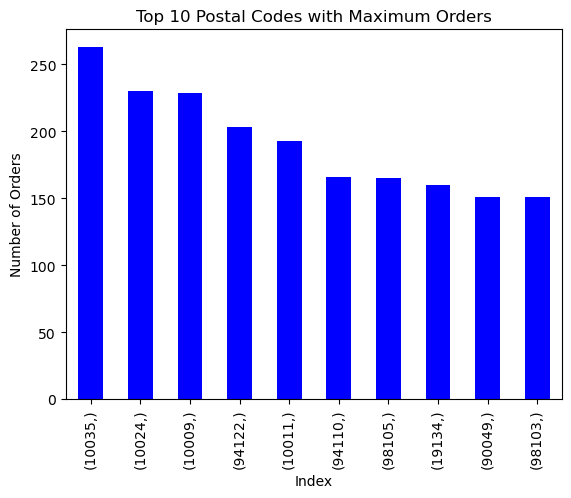

In [99]:
import matplotlib.pyplot as plt

x = range(0, 10)
data.plot(kind='bar',color='blue')
plt.title('Top 10 Postal Codes with Maximum Orders')
plt.xlabel('Index')
plt.ylabel('Number of Orders')

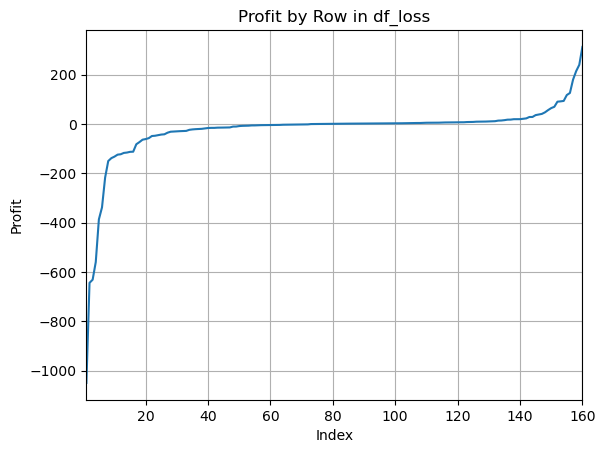

In [100]:
df_loss = df_store[df_store['Postal Code']==19134]
df_loss = df_loss.sort_values('Profit', ascending=True)

import matplotlib.pyplot as plt

x = range(1, len(df_loss) + 1)

plt.plot(x, df_loss["Profit"])
plt.xlabel("Index")
plt.ylabel("Profit")
plt.title("Profit by Row in df_loss")
plt.xlim(1, len(df_loss))
plt.grid(True)
plt.show()


<Axes: xlabel='Category'>

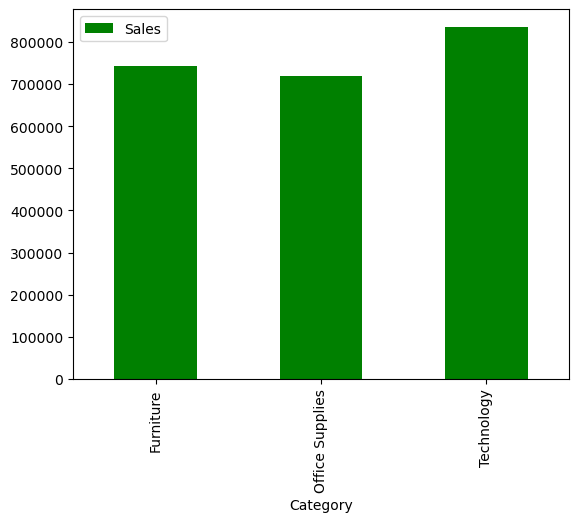

In [101]:
df_category= df_store[['Category','Sales','Profit']]

def profit_per_category(df_category):
    return df_category.groupby('Category').sum().reset_index()

df_category = profit_per_category(df_category)
df_category.plot(kind='bar', x='Category', y='Sales', color='green')

<Axes: xlabel='Category'>

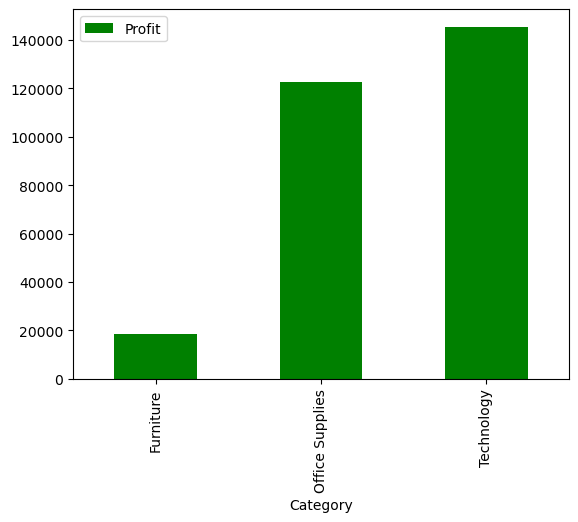

In [102]:
df_category= df_store[['Category','Profit']]

def profit_per_category(df_category):
    return df_category.groupby('Category').sum().reset_index()

df_category = profit_per_category(df_category)
df_category.plot(kind='bar', x='Category', y='Profit', color='green')

<Axes: ylabel='Profit'>

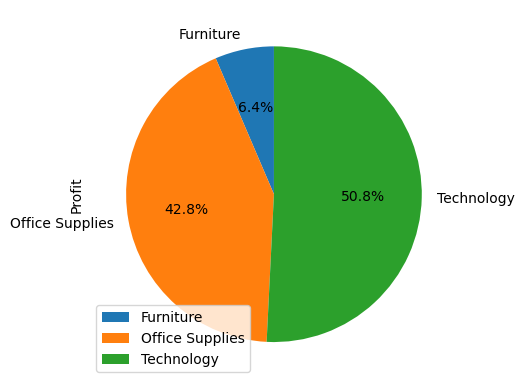

In [ ]:
df_category.plot(kind='pie', y='Profit', labels=df_category['Category'], autopct='%1.1f%%', startangle=90, legend=True)

<Axes: xlabel='Sub-Category'>

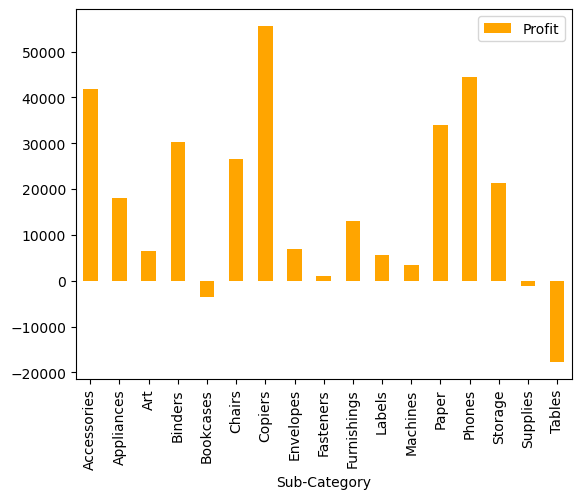

In [104]:
df_sub_category= df_store[['Sub-Category','Sales','Profit']]

def profit_per_sub_category(df_sub_category):
    return df_sub_category.groupby('Sub-Category').sum().reset_index()

df_sub_category = profit_per_sub_category(df_sub_category)
df_sub_category.plot(kind='bar', x='Sub-Category', y='Profit', color='orange')



In [105]:
df_tables= df_store[df_store['Sub-Category']=='Tables']

tables_postal_codes = df_tables['Postal Code'].value_counts()
tables_postal_codes


Postal Code
10024    11
90045     9
10011     8
94122     8
98115     7
         ..
10035     1
75002     1
60090     1
98226     1
45503     1
Name: count, Length: 163, dtype: int64

Text(0.5, 1.0, 'Top 10 Cities with Maximum Loss in Tables Sub-Category')

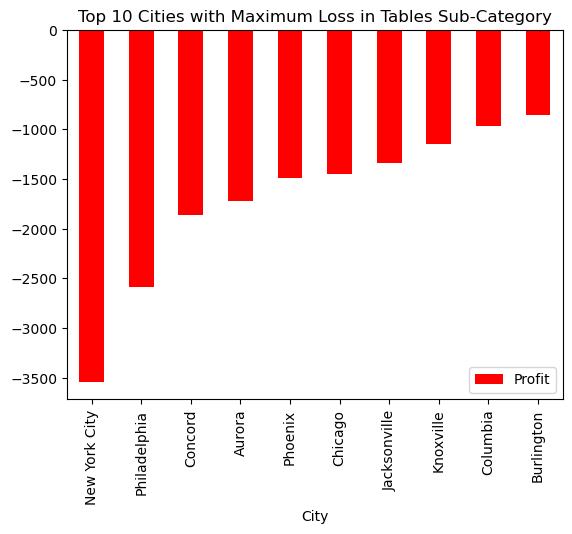

In [106]:
df_temp=df_tables.groupby('City').sum().reset_index().sort_values('Profit', ascending=True).head(10)

df_temp.plot(kind='bar', x='City', y='Profit', color='red')
plt.title('Top 10 Cities with Maximum Loss in Tables Sub-Category')

<Axes: xlabel='Region'>

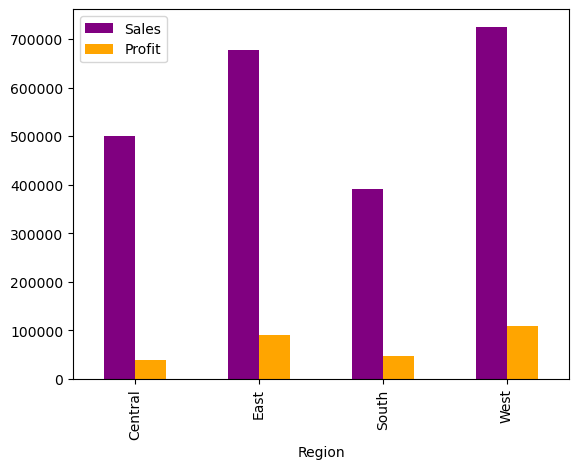

In [107]:
df_store_region = df_store.groupby('Region').sum().reset_index()
df_store_region.plot(kind='bar', x='Region', y=['Sales','Profit'], color=['purple','orange'])

<Axes: ylabel='Profit'>

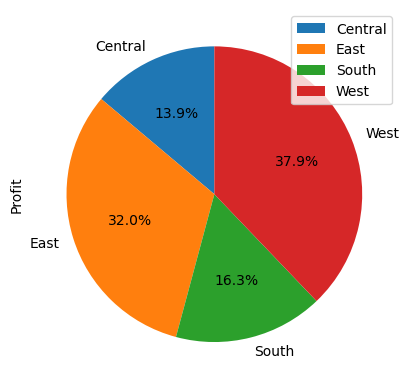

In [109]:
df_store_region.plot(kind='pie', y='Profit', labels=df_store_region['Region'], autopct='%1.1f%%', startangle=90, legend=True)

<Axes: ylabel='Sales'>

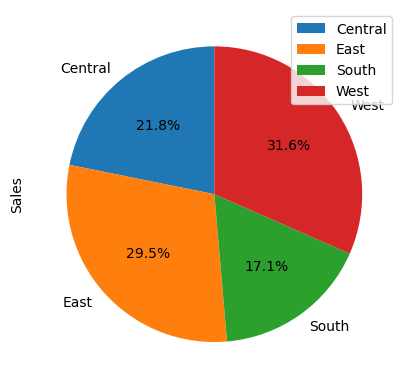

In [110]:
df_store_region.plot(kind='pie', y='Sales', labels=df_store_region['Region'], autopct='%1.1f%%', startangle=90, legend=True)

<Axes: xlabel='City'>

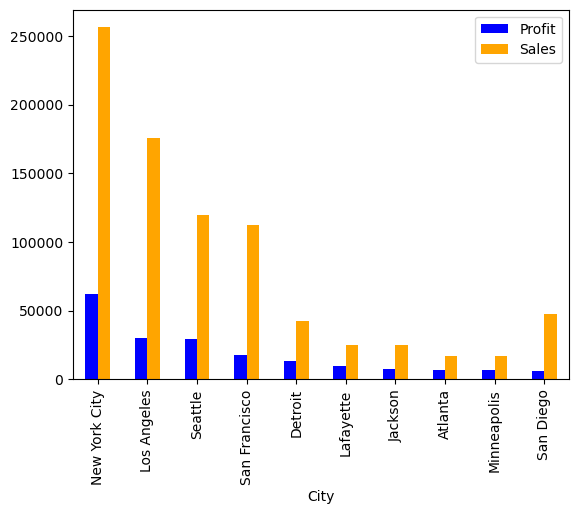

In [108]:
data2=df_store.groupby('City').sum().reset_index().sort_values('Profit', ascending=False).head(10)
data2.plot(kind='bar',x='City', y=['Profit', 'Sales'], color=['blue', 'orange'])